# Class 6: FDE Data Validation with FlashEats

Yesterday, you proved you could **retrieve** data from multiple systems.

Today the question is different:

> **Can we safely use that data to make a business decision?**

This is not a generic data-cleaning lab.

## FDE validation mindset

**Business claim → assumptions → validation contract → targeted checks → stakeholder clarification → PASS / WARN / FAIL → publish decision**

### Concepts

**1. Validation is decision-dependent**  
A field can be good enough for weekly reporting but unsafe for a live operational decision.

**2. Turn assumptions into contracts**  
Business assumption → data expectation → executable check → action.

**3. Separate three validation types**
- Technical: chronology, IDs, categories, mappings
- Semantic: what does a status or ETA actually mean?
- Organizational: who owns the KPI definition?

**4. Never silently fix ambiguity**  
Do not encode thresholds or category mappings without ownership.

**5. Output a validation gate**  
The deliverable is not merely a cleaned dataframe. It is a decision:
PASS / WARN / FAIL / UNKNOWN.

In [1]:
%pip install -q pandas matplotlib

import json
import numpy as np
import sqlite3
import zipfile
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 140)

# ------------------------------------------------------------
# Robust pack discovery for Colab / local runs
# ------------------------------------------------------------

def find_pack_root(search_root=Path("/content")):
    candidates = list(search_root.rglob("FlashEats_Classroom_Pack_V2"))
    for candidate in candidates:
        db = candidate / "database" / "flasheats.db"
        if db.exists():
            return candidate
    return None

# Local run: the notebook usually already lives inside the pack root.
BASE = None
if (Path.cwd() / "database" / "flasheats.db").exists():
    BASE = Path.cwd()
elif Path.cwd().name == "FlashEats_Classroom_Pack_V2":
    BASE = Path.cwd()

if BASE is None:
    BASE = find_pack_root()

if BASE is None:
    try:
        from google.colab import files

        print("Upload: FlashEats_Class6_Classroom_Pack.zip")
        uploaded = files.upload()

        zip_name = next(name for name in uploaded if name.endswith(".zip"))

        extract_dir = Path("/content/flasheats_class6")
        extract_dir.mkdir(parents=True, exist_ok=True)

        with zipfile.ZipFile(zip_name, "r") as z:
            z.extractall(extract_dir)

        BASE = find_pack_root(Path("/content"))

    except Exception as e:
        print("Automatic Colab setup failed:", e)

# Local fallback: search current working directory too
if BASE is None:
    BASE = find_pack_root(Path.cwd())

print("Detected BASE:", BASE)

if BASE is None:
    raise FileNotFoundError(
        "Could not find FlashEats_Classroom_Pack_V2. "
        "Upload/extract the classroom pack ZIP, then rerun this cell."
    )

DB_PATH = BASE / "database" / "flasheats.db"

print("Database path:", DB_PATH)
print("Database exists:", DB_PATH.exists())

if not DB_PATH.exists():
    raise FileNotFoundError(f"Database not found at {DB_PATH}")

Note: you may need to restart the kernel to use updated packages.


Detected BASE: /home/utkuputku/Desktop/flasheats-classroom-pack
Database path: /home/utkuputku/Desktop/flasheats-classroom-pack/database/flasheats.db
Database exists: True


## Load the updated FlashEats data

In [2]:
con = sqlite3.connect(BASE / "database" / "flasheats.db")

orders = pd.read_sql("SELECT * FROM orders", con)
restaurants = pd.read_sql("SELECT * FROM restaurants", con)
drivers = pd.read_sql("SELECT * FROM drivers", con)

tickets = pd.read_csv(BASE / "data" / "support_tickets.csv")
restaurant_status = pd.read_csv(BASE / "data" / "restaurant_status.csv")

with open(BASE / "data" / "client_metric_definitions.json", "r") as f:
    metric_notes = json.load(f)

print("orders:", orders.shape)
print("tickets:", tickets.shape)
print("restaurant_status:", restaurant_status.shape)

display(orders.head())
display(tickets.head())
display(restaurant_status.head())
print(json.dumps(metric_notes, indent=2))

orders: (1603, 13)
tickets: (202, 5)
restaurant_status: (502, 4)


,order_id,customer_id,restaurant_id,driver_id,city,created_at,promised_eta,pickup_at,actual_delivery_at,final_status,distance_km_estimate,traffic_bucket,weather_bucket
0,O00001,C0168,R009,D103,Bengaluru,2026-08-13T12:56:00,2026-08-13T14:11:36,2026-08-13T13:35:49.825561,2026-08-13T14:22:25.035899,delivered,18.00,medium,clear
1,O00002,C0043,R018,D083,Bengaluru,2026-08-01T18:36:00,2026-08-01T19:43:16.627988,2026-08-01T18:58:24.735336,2026-08-01T19:47:14.818533,delivered,9.37,severe,clear
2,O00003,C0855,R010,D039,Bengaluru,2026-08-01T19:35:00,2026-08-01T20:17:52.941967,2026-08-01T19:57:50.820366,2026-08-01T20:13:28.061191,delivered,2.42,medium,clear
3,O00004,C0229,R030,D038,Bengaluru,2026-08-09T18:16:00,2026-08-09T19:30:19.067006,2026-08-09T18:46:48.725485,NaN,cancelled,14.20,high,rain
4,O00005,C0040,R004,D047,Bengaluru,2026-08-06T20:35:00,2026-08-06T21:54:48,2026-08-06T21:18:38.024280,2026-08-06T22:15:49.290713,delivered,18.00,high,clear


,ticket_id,order_id,created_at,category,customer_message
0,T00001,NaN,2026-08-26T23:34:00,late_delivery,My order is already past the promised time.
1,T00002,NaN,2026-08-24T13:49:00,eta_changed,The ETA keeps changing and the food is still not here.
2,T00003,NaN,2026-08-25T18:22:00,status_mismatch,The app says picking up but the restaurant says it is ready.
3,T00004,O00037,2026-08-09T21:09:00,Late Delivery,The rider has not moved for 15 minutes.
4,T00005,O00040,2026-08-11T20:15:00,late_delivery,My order is already past the promised time.


,order_id,restaurant_id,status,last_updated_at
0,O00676,R040,READY,2026-08-17T13:29:00
1,O01506,R055,Ready,2026-08-27T16:37:00
2,O01484,R032,ready,2026-08-08T19:44:00
3,O00675,R012,handoff,2026-08-22T21:42:00
4,O00078,R027,unknown,2026-08-25T19:35:00


{
  "metric_under_review": "Late Delivery Rate",
  "leadership_claim": "Late Delivery Rate is 56%",
  "stakeholders": {
    "VP Operations": "Any delivered order after the promised ETA is late.",
    "Support Lead": "Only more than 10 minutes beyond ETA should count as meaningfully late.",
    "Finance": "Cancelled/refunded orders should not count in operational performance.",
    "Data Team": "Historical dashboard uses delivered orders with non-null actual delivery time."
  },
  "note": "No canonical KPI owner is formally documented."
}


# Challenge 1: Can we defend the “56% late” claim?


Leadership says:

> **“Late Delivery Rate is 56%.”**

Before calculating anything, create a validation contract.

| Business assumption | Data expectation | How will you test it? | Severity if false |
|---|---|---|---|
| One row = one business order |  |  |  |
| Delivered orders have completion time |  |  |  |
| Promised ETA is valid |  |  |  |
| Event chronology is valid |  |  |  |
| “Late” has an agreed definition |  |  |  |

**Hint:** Don't start by cleaning. Ask: *what could make 56% misleading?*

### My validation contract

| Business assumption | Data expectation | How will you test it? | Severity if false |
|---|---|---|---|
| One row = one business order | `order_id` unique in `orders` | rows vs unique ids, and check whether duplicate rows actually agree | High. Duplicates inflate both numerator and denominator, and conflicting copies mean we don't know which one is true |
| Delivered orders have completion time | every `delivered` order has `actual_delivery_at` | count delivered with null, then check whether the driver app has it | High. Whoever drops these silently changes the rate, and they aren't random |
| Promised ETA is valid | `promised_eta > created_at` | direct comparison | High for the orders affected, they show up as the worst delays when they're really broken data |
| Event chronology is valid | `created_at <= pickup_at <= actual_delivery_at` | direct comparison, plus cancelled orders shouldn't have a pickup | Medium for the late rate (it only uses promise and delivery), high for any "where does delay happen" analysis |
| "Late" has an agreed definition | one documented definition with an owner | read `client_metric_definitions.json` | Blocking. Four stakeholders, four definitions, no owner |

In [3]:
print("Rows:", len(orders))
print("Unique orders:", orders["order_id"].nunique())
print(orders["final_status"].value_counts(dropna=False))

# grain: are the duplicate rows identical?
dup = orders[orders["order_id"].duplicated(keep=False)].sort_values("order_id")
diff_cols = [c for c in orders.columns if dup.groupby("order_id")[c].nunique(dropna=False).gt(1).any()]
print("\nduplicate order_ids:", dup["order_id"].nunique(), "| columns where the copies disagree:", diff_cols)
display(dup[["order_id", "created_at", "actual_delivery_at"] + diff_cols])

o = orders.drop_duplicates("order_id", keep="first").copy()
for c in ["created_at", "promised_eta", "pickup_at", "actual_delivery_at"]:
    o[c] = pd.to_datetime(o[c], format="mixed", errors="coerce")
o["status_norm"] = o["final_status"].str.strip().str.lower()

Rows: 1603
Unique orders: 1600
final_status
delivered    1530
cancelled      68
Delivered       5
Name: count, dtype: int64

duplicate order_ids: 3 | columns where the copies disagree: ['traffic_bucket']


,order_id,created_at,actual_delivery_at,traffic_bucket
119,O00120,2026-08-13T18:15:00,2026-08-13T19:34:08.431508,severe
1600,O00120,2026-08-13T18:15:00,2026-08-13T19:34:08.431508,medium
722,O00723,2026-08-05T21:04:00,2026-08-05T22:04:30.928322,medium
1601,O00723,2026-08-05T21:04:00,2026-08-05T22:04:30.928322,high
1301,O01302,2026-08-26T21:07:00,2026-08-26T22:20:27.428561,medium
1602,O01302,2026-08-26T21:07:00,2026-08-26T22:20:27.428561,high


In [4]:
# second source for pickup/delivery: driver app events
with open(BASE / "data" / "driver_events.json") as f:
    driver_events = json.load(f)
ev = pd.DataFrame([{"driver_id": d["driver_id"], **e} for d in driver_events for e in d["events"]])
ev["timestamp"] = pd.to_datetime(ev["timestamp"], format="mixed")
app = (ev[ev["type"].isin(["picked_up", "delivered"])]
       .pivot_table(index="order_id", columns="type", values="timestamp", aggfunc="first")
       .rename(columns={"picked_up": "app_pickup_at", "delivered": "app_delivered_at"}))
o = o.merge(app, left_on="order_id", right_index=True, how="left")

delivered = o["status_norm"].eq("delivered")
checks = {
    "delivered, no actual_delivery_at": int((delivered & o["actual_delivery_at"].isna()).sum()),
    "  ...of those the driver app has a delivery time": int((delivered & o["actual_delivery_at"].isna() & o["app_delivered_at"].notna()).sum()),
    "  DB vs app delivery time agree where both exist": f"{((o['actual_delivery_at'] - o['app_delivered_at']).abs() < pd.Timedelta('1s'))[o['actual_delivery_at'].notna() & o['app_delivered_at'].notna()].mean():.0%}",
    "promised_eta before created_at": int((o["promised_eta"] < o["created_at"]).sum()),
    "pickup_at after actual_delivery_at": int((o["pickup_at"] > o["actual_delivery_at"]).sum()),
    "pickup_at before created_at": int((o["pickup_at"] < o["created_at"]).sum()),
    "cancelled orders that have a DB pickup_at": int((o["status_norm"].eq("cancelled") & o["pickup_at"].notna()).sum()),
    "cancelled orders the driver app actually picked up": int((o["status_norm"].eq("cancelled") & o["app_pickup_at"].notna()).sum()),
}
display(pd.Series(checks, name="result").to_frame())

print("broken promise times:")
display(o.loc[o["promised_eta"] < o["created_at"], ["order_id", "created_at", "promised_eta", "actual_delivery_at"]])
print("pickup after delivery (DB vs driver app):")
display(o.loc[o["pickup_at"] > o["actual_delivery_at"], ["order_id", "pickup_at", "app_pickup_at", "actual_delivery_at"]])

,result
"delivered, no actual_delivery_at",37
...of those the driver app has a delivery time,37
DB vs app delivery time agree where both exist,100%
promised_eta before created_at,4
pickup_at after actual_delivery_at,5
pickup_at before created_at,0
cancelled orders that have a DB pickup_at,68
cancelled orders the driver app actually picked up,0


broken promise times:


,order_id,created_at,promised_eta,actual_delivery_at
100,O00101,2026-08-24 20:59:00,2026-08-24 20:49:00,2026-08-24 22:14:30.685278
101,O00102,2026-08-11 16:41:00,2026-08-11 16:31:00,2026-08-11 17:57:17.661772
102,O00103,2026-08-22 20:11:00,2026-08-22 20:01:00,2026-08-22 21:10:17.342305
103,O00104,2026-08-09 22:19:00,2026-08-09 22:09:00,2026-08-09 23:36:20.740161


pickup after delivery (DB vs driver app):


,order_id,pickup_at,app_pickup_at,actual_delivery_at
50,O00051,2026-08-01 16:24:51.495665,2026-08-01 15:25:54.609569,2026-08-01 16:19:51.495665
51,O00052,2026-08-24 18:16:16.946011,2026-08-24 17:19:34.353083,2026-08-24 18:11:16.946011
52,O00053,2026-08-13 18:25:53.797613,2026-08-13 17:42:23.641275,2026-08-13 18:20:53.797613
53,O00054,2026-08-28 21:25:10.582862,2026-08-28 20:23:52.944934,2026-08-28 21:20:10.582862
54,O00055,2026-08-16 14:08:05.645770,2026-08-16 13:20:04.394373,2026-08-16 14:03:05.645770


Challenge 1 findings:
- Grain fails as stored. 1,603 rows for 1,600 orders, and the 3 duplicate pairs disagree on `traffic_bucket`, so they're not harmless copies. Dedupe for the late rate is safe (the timestamps match), but which traffic value is right needs the source team.
- 37 delivered orders have no completion time. The driver app has all 37 and matches the DB 100% wherever both exist, so this is recoverable, not unknowable.
- 4 promises are before the order was created (O00101 to O00104, all exactly 10 min before). Looks like a bug, not a real promise.
- 5 DB pickups are after delivery (O00051 to O00055, exactly 5 min after). Driver app pickups are fine.
- All 68 cancelled orders have a pickup time in the DB, but the driver app never picked any of them up. DB pickup on cancelled orders means nothing.
- "Late" has no owner. That's the one that actually blocks publishing.

What could make 56% misleading: it's the old dashboard number, which quietly drops the 37 missing orders and keeps the 4 broken ETAs. And it's "any lateness at all", which a lot of people will read as "customers got their food really late".

# Challenge 2: Stakeholders disagree on “late”


Read `client_metric_definitions.json`.

Calculate the metric under at least three definitions:
- any delay > 0 minutes,
- delay > 10 minutes,
- historical-style delivered/non-null population.

| Definition | Late rate | Business meaning |
|---|---:|---|

Then answer:

> **Which one should leadership publish, and who must own that decision?**

In [5]:
analysis = o.copy()
analysis["delivered_at"] = analysis["actual_delivery_at"].fillna(analysis["app_delivered_at"])
analysis["delay_min"] = (analysis["delivered_at"] - analysis["promised_eta"]).dt.total_seconds() / 60
analysis["db_delay_min"] = (analysis["actual_delivery_at"] - analysis["promised_eta"]).dt.total_seconds() / 60
bad_eta = analysis["promised_eta"] < analysis["created_at"]
deliv = analysis["status_norm"].eq("delivered")

# Finance wants refunds out too. no refund field here, closest thing is CUSTOMER_CREDIT in order_interventions
credits = pd.read_csv(BASE / "data" / "order_interventions.csv").query("intervention_type == 'CUSTOMER_CREDIT'")["order_id"]
credited = analysis["order_id"].isin(credits)

raw = orders.copy()
for c in ["promised_eta", "actual_delivery_at"]:
    raw[c] = pd.to_datetime(raw[c], format="mixed")
raw_delay = (raw["actual_delivery_at"] - raw["promised_eta"]).dt.total_seconds() / 60

def row(name, delay, mask, thresh, meaning):
    x = delay[mask]
    return {"definition": name, "orders": int(mask.sum()), "late": int((x > thresh).sum()),
            "late_rate_%": round((x > thresh).mean() * 100, 1), "business meaning": meaning}

valid = deliv & analysis["delivered_at"].notna() & ~bad_eta
defs = pd.DataFrame([
    row("Data Team: historical dashboard (DB delivered, non-null, >0)", analysis["db_delay_min"], deliv & analysis["actual_delivery_at"].notna(), 0,
        "reproduces the 56% claim, silently drops 37 orders"),
    row("VP Ops: any delay > 0, validated population", analysis["delay_min"], valid, 0,
        "did we keep the promise we made"),
    row("Support: delay > 10 min, validated population", analysis["delay_min"], valid, 10,
        "late enough that customers feel it"),
    row("Finance: > 0, excl. cancelled and credited orders", analysis["delay_min"], valid & ~credited, 0,
        "operational performance without service-recovery orders"),
    row("naive: raw rows incl. dupes, all rows as denominator", raw_delay, pd.Series(True, index=raw.index), 0,
        "what you get if nobody checks anything"),
])
display(defs)

,definition,orders,late,late_rate_%,business meaning
0,"Data Team: historical dashboard (DB delivered, non-null, >0)",1495,843,56.4,"reproduces the 56% claim, silently drops 37 orders"
1,"VP Ops: any delay > 0, validated population",1528,863,56.5,did we keep the promise we made
2,"Support: delay > 10 min, validated population",1528,354,23.2,late enough that customers feel it
3,"Finance: > 0, excl. cancelled and credited orders",1466,822,56.1,operational performance without service-recovery orders
4,"naive: raw rows incl. dupes, all rows as denominator",1603,844,52.7,what you get if nobody checks anything


Challenge 2 answer:

The 56% is real, but only under one definition: the old dashboard one (56.4%). That's "any lateness at all", on a population that silently loses 37 orders and keeps 4 broken ETAs. Fixing the population barely moves it (56.5%), so the data problems aren't what makes 56% misleading. The definition is.

- Any delay > 0: ~56%. Did we keep the promise?
- More than 10 min: ~23%. Did the customer actually get hurt?
- Finance version: 56.1%, about the same as ops, because cancelled orders are already out and only 62 of the delivered orders got a credit. Also the pack has no refund field, so "refunded" can only be approximated with CUSTOMER_CREDIT.

What I'd tell leadership to publish: both numbers side by side, "56% missed the promised time, 23% were more than 10 min late", with the definition written next to each. Publishing 56% alone makes it sound like most customers are getting food super late, when the median late order is ~8 min over.

Who owns it: nobody right now, `client_metric_definitions.json` literally says no owner is documented. I'd make VP Operations the owner (they own the promise and can act on it), with Support signing off on the >10 min threshold and Finance on exclusions. The data team shouldn't be picking the definition, it just implements it.

# Challenge 3: Validate categories without cleaning by instinct


Inspect:
- `final_status`
- `traffic_bucket`
- restaurant `status`
- support-ticket `category`

For each:
1. list observed values,
2. identify representation differences,
3. decide what is safe to normalize,
4. identify what requires owner confirmation.

Remember:

> `"Delivered"` vs `"delivered"` is likely representation.  
> `"handoff"` vs `"handed_off"` may be semantics.

In [6]:
for col in ["final_status", "traffic_bucket"]:
    print("\n", col)
    print(orders[col].value_counts(dropna=False))

print("\nRestaurant status")
print(restaurant_status["status"].value_counts(dropna=False))

print("\nSupport category")
print(tickets["category"].value_counts(dropna=False))


 final_status
final_status
delivered    1530
cancelled      68
Delivered       5
Name: count, dtype: int64

 traffic_bucket
traffic_bucket
medium    635
high      448
low       381
severe    136
HIGH        3
Name: count, dtype: int64

Restaurant status
status
preparing     171
handed_off    168
ready         157
ready           2
READY           1
Ready           1
handoff         1
unknown         1
Name: count, dtype: int64

Support category
category
late_delivery        38
eta_changed          37
restaurant_delay     37
ready_but_waiting    33
status_mismatch      29
driver_not_moving    25
Late Delivery         1
late_delivery         1
ETA issue             1
Name: count, dtype: int64


In [7]:
restaurant_status = restaurant_status.copy()
restaurant_status["status_raw"] = restaurant_status["status"].map(repr)
print("restaurant status with whitespace visible:")
print(restaurant_status["status_raw"].value_counts())

tickets = tickets.copy()
print("\nticket category with whitespace visible:")
print(tickets["category"].map(repr).value_counts())

# which messages go with the odd categories?
odd = tickets[~tickets["category"].isin(["late_delivery", "eta_changed", "restaurant_delay", "ready_but_waiting", "status_mismatch", "driver_not_moving"])]
display(odd[["ticket_id", "order_id", "category", "customer_message"]])

# what does the one "handoff" record look like next to "handed_off"?
display(restaurant_status[restaurant_status["status"].str.strip().str.lower().isin(["handoff", "unknown"])])

restaurant status with whitespace visible:
status_raw
'preparing'     171
'handed_off'    168
'ready'         157
'ready '          2
'READY'           1
'Ready'           1
'handoff'         1
'unknown'         1
Name: count, dtype: int64

ticket category with whitespace visible:
category
'late_delivery'        38
'eta_changed'          37
'restaurant_delay'     37
'ready_but_waiting'    33
'status_mismatch'      29
'driver_not_moving'    25
'Late Delivery'         1
'late_delivery '        1
'ETA issue'             1
Name: count, dtype: int64


,ticket_id,order_id,category,customer_message
3,T00004,O00037,Late Delivery,The rider has not moved for 15 minutes.
4,T00005,O00040,late_delivery,My order is already past the promised time.
5,T00006,O00041,ETA issue,The rider has not moved for 15 minutes.


,order_id,restaurant_id,status,last_updated_at,status_raw
3,O00675,R012,handoff,2026-08-22T21:42:00,'handoff'
4,O00078,R027,unknown,2026-08-25T19:35:00,'unknown'


In [8]:
# only representation fixes. meaning questions stay as they are and get flagged
def normalize_representation(s):
    return s.str.strip().str.lower().str.replace(" ", "_", regex=False)

o["final_status_clean"] = normalize_representation(o["final_status"])
o["traffic_clean"] = normalize_representation(o["traffic_bucket"])
restaurant_status["status_clean"] = normalize_representation(restaurant_status["status"])
tickets["category_clean"] = normalize_representation(tickets["category"])

needs_owner = {
    "restaurant status 'handoff'": "same as 'handed_off'? or a different step, like handoff started?",
    "restaurant status 'unknown'": "missing value or a real state?",
    "ticket category 'eta_issue'": "message says rider hasn't moved, so maybe driver_not_moving, but that's support's call",
    "ticket T00004 'Late Delivery'": "message says rider hasn't moved, category and message disagree",
    "traffic on duplicate orders": "3 orders have two different traffic values, which one is true?",
}
for col, s in [("final_status", o["final_status_clean"]), ("traffic", o["traffic_clean"]),
               ("restaurant status", restaurant_status["status_clean"]), ("ticket category", tickets["category_clean"])]:
    print(col, {k: int(v) for k, v in s.value_counts().items()})
print()
display(pd.Series(needs_owner, name="question for the owner").to_frame())

final_status {'delivered': 1532, 'cancelled': 68}
traffic {'medium': 634, 'high': 449, 'low': 381, 'severe': 136}
restaurant status {'preparing': 171, 'handed_off': 168, 'ready': 161, 'handoff': 1, 'unknown': 1}
ticket category {'late_delivery': 40, 'eta_changed': 37, 'restaurant_delay': 37, 'ready_but_waiting': 33, 'status_mismatch': 29, 'driver_not_moving': 25, 'eta_issue': 1}



,question for the owner
restaurant status 'handoff',"same as 'handed_off'? or a different step, like handoff started?"
restaurant status 'unknown',missing value or a real state?
ticket category 'eta_issue',"message says rider hasn't moved, so maybe driver_not_moving, but that's support's call"
ticket T00004 'Late Delivery',"message says rider hasn't moved, category and message disagree"
traffic on duplicate orders,"3 orders have two different traffic values, which one is true?"


Challenge 3 answer:

| Field | Observed | Safe to normalize | Needs owner |
|---|---|---|---|
| `final_status` | delivered, Delivered, cancelled | `Delivered` -> `delivered`, just casing | nothing |
| `traffic_bucket` | low, medium, high, severe, HIGH | `HIGH` -> `high` | the 3 duplicate orders with two different traffic values. Also nobody's said what the buckets mean (speed? a vendor score?) |
| restaurant `status` | preparing, ready, handed_off, `ready `, `READY`, `Ready`, handoff, unknown | the `ready` variants (spaces and casing) | `handoff` vs `handed_off` could be the same thing or a different step. `unknown` could be missing or a real state. Only 2 rows, but don't guess |
| ticket `category` | 6 clean values + `Late Delivery`, `late_delivery `, `ETA issue` | `Late Delivery` and `late_delivery ` -> `late_delivery` | `ETA issue` isn't any existing category, and its message says the rider hasn't moved. T00004 is filed as late delivery but the message says the same thing. Support owns that taxonomy |

The row counts are tiny, but it's the principle: if I map `handoff` to `handed_off` on a hunch and it's actually a different step, I've quietly changed what the metric means.

# Challenge 4: Cross-source integrity


Validate mappings:
- `orders.restaurant_id` → restaurants
- `orders.driver_id` → drivers
- `tickets.order_id` → orders
- `restaurant_status.order_id` → orders

Produce:

| Relationship | Coverage % | Status | Risk |
|---|---:|---|---|

Then discuss:

> If 1% is unmapped, is that acceptable?

It depends on which business decision uses those records.

In [9]:
drivers = pd.read_sql("SELECT * FROM drivers", con)
t = tickets.drop_duplicates()
rs = restaurant_status.drop_duplicates(subset=["order_id", "restaurant_id", "status", "last_updated_at"])

def coverage(name, child_keys, parent_keys, risk):
    n = len(child_keys)
    nulls = int(child_keys.isna().sum())
    mapped = int(child_keys.dropna().isin(parent_keys).sum())
    pct = mapped / n * 100
    status = "PASS" if pct == 100 else ("WARN" if pct >= 95 else "FAIL")
    return {"relationship": name, "rows": n, "null key": nulls, "mapped": mapped,
            "coverage_%": round(pct, 2), "non-null mapped_%": round(mapped / max(n - nulls, 1) * 100, 1), "status": status, "risk": risk}

rel = pd.DataFrame([
    coverage("orders.restaurant_id -> restaurants", o["restaurant_id"], restaurants["restaurant_id"],
             "3 orders can't be attributed to any restaurant"),
    coverage("orders.driver_id -> drivers", o["driver_id"], drivers["driver_id"],
             "3 nulls, and for 95 reassigned orders this is the original driver, not who delivered"),
    coverage("tickets.order_id -> orders", t["order_id"], o["order_id"],
             "3 tickets can't be tied to an order"),
    coverage("restaurant_status.order_id -> orders", rs["order_id"], o["order_id"],
             "maps fine, but only covers a third of orders"),
])
display(rel)

print("the other direction, how much of the order base each source covers:")
print(f"  orders with a restaurant status record: {o['order_id'].isin(rs['order_id']).mean():.0%}")
print(f"  orders with a ticket: {o['order_id'].isin(t['order_id']).mean():.0%}")
chk = rs.merge(o[["order_id", "restaurant_id"]], on="order_id", suffixes=("", "_orders"))
print(f"  restaurant_status.restaurant_id agrees with orders.restaurant_id: {(chk['restaurant_id'] == chk['restaurant_id_orders']).mean():.0%}")
print("  exact duplicate rows dropped: tickets", len(tickets) - len(t), "| restaurant_status", len(restaurant_status) - len(rs))

# driver attribution: who actually delivered?
real_driver = ev.groupby("order_id")["driver_id"].first()
print(f"  orders.driver_id != driver in the driver app: {(o.set_index('order_id')['driver_id'] != real_driver).sum()} (incl. the 3 nulls)")

,relationship,rows,null key,mapped,coverage_%,non-null mapped_%,status,risk
0,orders.restaurant_id -> restaurants,1600,3,1597,99.81,100.0,WARN,3 orders can't be attributed to any restaurant
1,orders.driver_id -> drivers,1600,3,1597,99.81,100.0,WARN,"3 nulls, and for 95 reassigned orders this is the original driver, not who delivered"
2,tickets.order_id -> orders,201,3,198,98.51,100.0,WARN,3 tickets can't be tied to an order
3,restaurant_status.order_id -> orders,500,0,500,100.00,100.0,PASS,"maps fine, but only covers a third of orders"


the other direction, how much of the order base each source covers:
  orders with a restaurant status record: 31%
  orders with a ticket: 12%
  restaurant_status.restaurant_id agrees with orders.restaurant_id: 100%
  exact duplicate rows dropped: tickets 1 | restaurant_status 2
  orders.driver_id != driver in the driver app: 98 (incl. the 3 nulls)


Challenge 4 answer:

Every non-null key maps. The gaps are nulls and coverage, not broken ids:
- restaurants: 99.8%, 3 orders with no restaurant. WARN
- drivers: 99.8% by key, but the key means the wrong thing for 95 reassigned orders. `orders.driver_id` is the first driver assigned, the driver app shows someone else delivered. WARN, and FAIL if you're using it to rank drivers
- tickets: 98.5% (3 of 201 have no order). WARN
- restaurant_status: 100% of its rows map, but it only exists for ~31% of orders. That's a coverage problem, not a mapping one

Is 1% unmapped OK? For the company-wide late rate, yes. 3 orders out of 1,528 won't move a percentage. For a restaurant scorecard, the 3 unattributed orders are fine, but only having status for a third of orders is not. For driver performance, it's not about 1% at all, 6% of orders are pinned on the wrong driver. Same data, different answer depending on what it's used for.

# Challenge 5: Freshness is an SLA question


Use `restaurant_status.csv`.

Determine whether status updates are fresh enough for:
- weekly analytics,
- live customer ETA,
- restaurant accountability.

The same record may be acceptable for one use case and unsafe for another.

**Hint:** join status records to order lifecycle timestamps and inspect timing.

In [10]:
fr = rs.merge(o[["order_id", "created_at", "pickup_at", "app_pickup_at", "actual_delivery_at", "final_status_clean"]], on="order_id", how="left")
fr["updated_at"] = pd.to_datetime(fr["last_updated_at"], format="mixed")
fr["pickup"] = fr["app_pickup_at"].fillna(fr["pickup_at"])  # driver app pickup is the trustworthy one
fr["min_after_order"] = (fr["updated_at"] - fr["created_at"]).dt.total_seconds() / 60
fr["min_vs_pickup"] = (fr["updated_at"] - fr["pickup"]).dt.total_seconds() / 60
fr["min_before_delivery"] = (fr["actual_delivery_at"] - fr["updated_at"]).dt.total_seconds() / 60

print("records per order:", fr.groupby("order_id").size().value_counts().to_dict(), "-> one snapshot, no history")
print("\nminutes, by status:")
display(fr.groupby("status_clean")[["min_after_order", "min_vs_pickup", "min_before_delivery"]].median().round(1))

weird = fr[fr["min_after_order"] < 0]
print("status updated BEFORE the order existed:", len(weird))
display(weird[["order_id", "status", "last_updated_at", "created_at", "min_after_order"]])

records per order: {1: 500} -> one snapshot, no history

minutes, by status:


,min_after_order,min_vs_pickup,min_before_delivery
status_clean,,,
handed_off,19.0,-6.2,51.8
handoff,22.0,8.1,NaN
preparing,19.0,-7.3,55.2
ready,24.0,-5.2,55.2
unknown,17.0,-3.2,56.0


status updated BEFORE the order existed: 5


,order_id,status,last_updated_at,created_at,min_after_order
5,O01016,handed_off,2026-08-17T08:01:00,2026-08-17 13:46:00,-345.0
6,O01395,ready,2026-08-21T09:45:00,2026-08-21 15:27:00,-342.0
7,O00925,preparing,2026-08-10T11:20:00,2026-08-10 17:10:00,-350.0
8,O00788,ready,2026-08-03T06:10:00,2026-08-03 11:58:00,-348.0
9,O01168,ready,2026-08-16T07:49:00,2026-08-16 13:43:00,-354.0


orders whose last known status is 'preparing' even though the driver already picked up: 169 of 169
'ready' updates that came after the driver already picked up: 12% of ready
'handed_off' updates stamped before the pickup happened: 110 of 167
status age at delivery (median): 53 min
timestamps are minute precision only: True


,min_after_order,min_vs_pickup
manual_status_updates,,
automated,21.0,-6.3
manual,20.0,-5.9


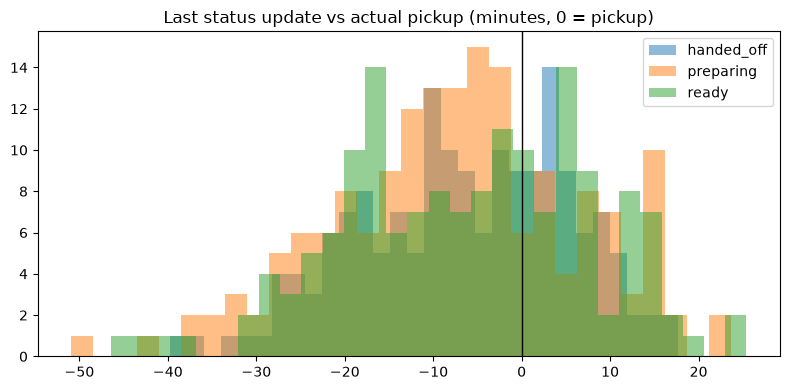

In [11]:
ok = fr[fr["min_after_order"] >= 0]
picked = ok["pickup"].notna()
print(f"orders whose last known status is 'preparing' even though the driver already picked up: "
      f"{(ok['status_clean'].eq('preparing') & picked).sum()} of {ok['status_clean'].eq('preparing').sum()}")
print(f"'ready' updates that came after the driver already picked up: {(ok['status_clean'].eq('ready') & (ok['min_vs_pickup'] > 0)).mean() * 100:.0f}% of ready")
print(f"'handed_off' updates stamped before the pickup happened: {(ok['status_clean'].eq('handed_off') & (ok['min_vs_pickup'] < 0)).sum()} of {ok['status_clean'].eq('handed_off').sum()}")
print(f"status age at delivery (median): {ok['min_before_delivery'].median():.0f} min")
print("timestamps are minute precision only:", (fr["updated_at"].dt.second == 0).all())

# manual vs automated restaurants
m = ok.merge(restaurants[["restaurant_id", "manual_status_updates"]], on="restaurant_id")
display(m.groupby("manual_status_updates")[["min_after_order", "min_vs_pickup"]].median().round(1)
         .rename(index={0: "automated", 1: "manual"}))

fig, ax = plt.subplots(figsize=(8, 4))
for s_, g in ok.groupby("status_clean"):
    if len(g) > 10:
        ax.hist(g["min_vs_pickup"], bins=30, alpha=0.5, label=s_)
ax.axvline(0, color="black", lw=1)
ax.set_title("Last status update vs actual pickup (minutes, 0 = pickup)")
ax.legend()
plt.tight_layout()
plt.show()

Challenge 5 answer:

The feed is one snapshot per order, not a stream of updates. There's no history, so you only see whatever the last thing someone clicked was. On top of that:
- 5 records are stamped ~6 hours before the order even existed. Looks like a clock or timezone bug on some sources.
- All 169 orders whose last status is "preparing" were actually picked up. The status just never moved forward.
- 110 of 167 "handed_off" updates are stamped before the actual pickup, so the restaurant says it's handed over before the driver has it.
- By the time the food arrives, the last status is ~53 min old on median.
- Updates are minute precision only.

Fit for purpose:
- Weekly analytics: WARN. Fine for rough counts like "how often do restaurants update at all", as long as you drop the 5 bad timestamps and don't read the status as the true final state.
- Live customer ETA: FAIL. One snapshot, often stale, sometimes just wrong ("preparing" after pickup). Showing this to customers is probably how you get the "app says picking up but restaurant says ready" tickets.
- Restaurant accountability: FAIL. You can't hold a restaurant to "food ready by X" when the ready signal is a manual click that may never happen and has no history. You'd need a real `food_ready_at` event before this is fair to restaurants.

# Challenge 6: Build the validation gate


Summarize the investigation:

| Check | Status | Evidence | Action |
|---|---|---|---|
| Business grain |  |  |  |
| Timestamp chronology |  |  |  |
| KPI definition |  |  |  |
| Category semantics |  |  |  |
| Cross-source mapping |  |  |  |
| Freshness |  |  |  |

Use only:
**PASS / WARN / FAIL / UNKNOWN**

Finally answer:

> **Should leadership publish “Late Delivery Rate = 56%” today?**

What exactly must happen before the metric becomes publishable?

In [12]:
validation_report = {
    "business_grain": {
        "status": "WARN",
        "evidence": "1,603 rows / 1,600 orders; 3 duplicate pairs disagree on traffic_bucket",
        "action": "dedupe on order_id for the KPI; source team to fix the upstream duplicate and say which traffic value is right"},
    "timestamp_chronology": {
        "status": "WARN",
        "evidence": "37 delivered with no delivery time (recoverable from driver app, 100% match), 4 ETAs before creation, 5 pickups after delivery, fake pickups on 68 cancelled orders",
        "action": "backfill the 37 from the driver app and flag them, exclude the 4 broken ETAs, file bugs for the rest"},
    "kpi_definition": {
        "status": "FAIL",
        "evidence": "4 stakeholder definitions give 23% to 56.5%; no documented owner",
        "action": "name an owner (VP Ops suggested), sign off on threshold and exclusions"},
    "category_semantics": {
        "status": "WARN",
        "evidence": "casing/space variants are safe to fix; handoff vs handed_off, unknown and 'ETA issue' need owner calls",
        "action": "normalize representation only; send the rest to restaurant ops and support"},
    "cross_source_mapping": {
        "status": "WARN",
        "evidence": "all non-null keys map; 3 null restaurant/driver ids, 3 orphan tickets; orders.driver_id is the original driver for 95 reassigned orders",
        "action": "fine for the company KPI; use dispatch or the driver app for anything driver level"},
    "freshness": {
        "status": "FAIL",
        "evidence": "one snapshot per order, all 169 'preparing' records were already picked up, 5 stamped ~6h before the order existed",
        "action": "not needed for the late rate itself; block use for live ETA and restaurant accountability"},
    "publish_56_percent": {
        "status": "NO, not as it stands",
        "evidence": "56% only reproduces under the old dashboard definition, which has no owner",
        "action": "publish the validated number with its definition, next to the >10 min number, once an owner signs off"},
}
display(pd.DataFrame(validation_report).T)

,status,evidence,action
business_grain,WARN,"1,603 rows / 1,600 orders; 3 duplicate pairs disagree on traffic_bucket",dedupe on order_id for the KPI; source team to fix the upstream duplicate and say which traffic value is right
timestamp_chronology,WARN,"37 delivered with no delivery time (recoverable from driver app, 100% match), 4 ETAs before creation, 5 pickups after delivery, fake pic...","backfill the 37 from the driver app and flag them, exclude the 4 broken ETAs, file bugs for the rest"
kpi_definition,FAIL,4 stakeholder definitions give 23% to 56.5%; no documented owner,"name an owner (VP Ops suggested), sign off on threshold and exclusions"
category_semantics,WARN,"casing/space variants are safe to fix; handoff vs handed_off, unknown and 'ETA issue' need owner calls",normalize representation only; send the rest to restaurant ops and support
cross_source_mapping,WARN,"all non-null keys map; 3 null restaurant/driver ids, 3 orphan tickets; orders.driver_id is the original driver for 95 reassigned orders",fine for the company KPI; use dispatch or the driver app for anything driver level
freshness,FAIL,"one snapshot per order, all 169 'preparing' records were already picked up, 5 stamped ~6h before the order existed",not needed for the late rate itself; block use for live ETA and restaurant accountability
publish_56_percent,"NO, not as it stands","56% only reproduces under the old dashboard definition, which has no owner","publish the validated number with its definition, next to the >10 min number, once an owner signs off"


### Should leadership publish "Late Delivery Rate = 56%" today?

No. Not because the number is wrong, it reproduces fine (56.4%, and 56.5% after fixing the population). The problem is it's one definition nobody owns, and on its own it tells a scarier story than the data. The median late order is 8 minutes over, and only ~23% are more than 10 minutes late.

What has to happen before it's publishable:
1. Someone owns the KPI. I'd suggest VP Ops, with Support and Finance signing off on the threshold and exclusions.
2. The definition gets written down: which population, what counts as late, what's excluded.
3. The data team uses the validated population: dedupe, driver-app backfill for the 37, drop the 4 broken ETAs. It's all logged so the number can be reproduced.
4. Publish it as two numbers: "56.5% missed the promised time, 23% were more than 10 min late."

Freshness and restaurant status don't block this KPI, since it doesn't use them, but they do block the next thing people will ask for, like "which restaurants are causing it".

# Final takeaway

The job was not to make the data look clean.

The job was to decide:

> **Is this data safe enough for this decision, and what remains unresolved?**